# 03 - Business Questions with SQL

In this notebook I answer business questions using **SQL** on the SQLite database created in `01_data_cleaning.ipynb`.

The queries go from basic to more advanced, so each one also shows a different SQL concept:
`JOIN`, `GROUP BY` / `HAVING`, `CASE WHEN`, subqueries, CTEs (`WITH`) and window functions (`RANK`, `LAG`, `SUM OVER`).

All the queries are also saved in [`sql/business_questions.sql`](../sql/business_questions.sql), so they can be run in any SQL tool (e.g. DB Browser for SQLite, DBeaver).

**The database has 4 tables:**

```
customers (customer_id) ──< orders (order_id) ──< order_items >── products (product_id)
```
- one customer has many orders
- one order has one or more lines (`order_items`)
- each line is one product

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
MAIN_COLOR = "#2a78d6"

conn = sqlite3.connect("../data/sales.db")


def run_query(query):
    """Run a SQL query on the database and return the result as a pandas DataFrame."""
    return pd.read_sql_query(query, conn)

In [2]:
# list the tables in the database and their number of rows
tables = run_query("SELECT name FROM sqlite_master WHERE type = 'table'")

for table in tables["name"]:
    n_rows = run_query(f"SELECT COUNT(*) AS n FROM {table}")["n"][0]
    columns = run_query(f"PRAGMA table_info({table})")["name"].tolist()
    print(f"{table} ({n_rows:,} rows): {', '.join(columns)}")

customers (7,962 rows): customer_id, customer_name, segment, city, state, region
products (27 rows): product_id, product_name, category, sub_category, unit_price, cost_price
orders (60,000 rows): order_id, order_date, ship_date, deliver_date, ship_mode, customer_id, payment_method
order_items (80,915 rows): order_id, product_id, quantity, discount, sales, profit, order_status, is_returned


## A. Sales performance

### Q1. What are the revenue, profit and margin in each year?

*SQL used:* `JOIN` between two tables, `GROUP BY`, aggregate functions and `strftime` to get the year from the date.

In [3]:
query = """
SELECT
    strftime('%Y', o.order_date)                       AS year,
    COUNT(DISTINCT o.order_id)                         AS orders,
    COUNT(DISTINCT o.customer_id)                      AS customers,
    ROUND(SUM(oi.sales), 0)                            AS revenue,
    ROUND(SUM(oi.profit), 0)                           AS profit,
    ROUND(SUM(oi.profit) * 100.0 / SUM(oi.sales), 1)   AS margin_pct,
    ROUND(SUM(oi.sales) / COUNT(DISTINCT o.order_id), 2) AS avg_order_value
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
GROUP BY year
ORDER BY year;
"""

result = run_query(query)
result

,year,orders,customers,revenue,profit,margin_pct,avg_order_value
0,2023,30066,7547,17902315.0,5154851.0,28.8,595.43
1,2024,29934,7548,17831149.0,5123161.0,28.7,595.68


**Answer:** 2023 and 2024 are almost the same: ~17.9M USD revenue, ~5.1M USD profit and 28.8% margin in both years.
The number of orders, customers and the average order value (~596 USD) also didn't change. The business is stable, but not growing.

### Q2. How did revenue change month by month in 2024, compared with the previous month and with the same month of 2023?

*SQL used:* A **CTE** (`WITH`) and the window function `LAG()`. The filter for 2024 is done in the end, in a second CTE - if I put the `WHERE` before `LAG()`, the 2023 months would disappear before the calculation and January 2024 would have nothing to compare with.

In [4]:
query = """
WITH monthly AS (
    SELECT
        strftime('%Y-%m', o.order_date) AS month,
        SUM(oi.sales)                   AS revenue
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
    GROUP BY month
),
with_previous AS (
    SELECT
        month,
        revenue,
        LAG(revenue, 1)  OVER (ORDER BY month) AS previous_month,
        LAG(revenue, 12) OVER (ORDER BY month) AS same_month_last_year
    FROM monthly
)
SELECT
    month,
    ROUND(revenue, 0)                                                   AS revenue,
    ROUND((revenue - previous_month) * 100.0 / previous_month, 1)       AS vs_previous_month_pct,
    ROUND((revenue - same_month_last_year) * 100.0 / same_month_last_year, 1) AS vs_last_year_pct
FROM with_previous
WHERE month >= '2024-01'
ORDER BY month;
"""

result = run_query(query)
result

,month,revenue,vs_previous_month_pct,vs_last_year_pct
0,2024-01,882473.0,-73.2,-8.1
1,2024-02,812950.0,-7.9,0.8
2,2024-03,1265310.0,55.6,-2.5
3,2024-04,1276964.0,0.9,-6.4
4,2024-05,1302015.0,2.0,0.7
5,2024-06,1267579.0,-2.6,2.2
6,2024-07,1243170.0,-1.9,-7.8
7,2024-08,1346340.0,8.3,5.2
8,2024-09,1210970.0,-10.1,-4.5
9,2024-10,1335905.0,10.3,9.5


**Answer:** Compared with 2023, the months of 2024 go up and down between -8% and +10%, with no clear trend - it's mostly noise.
The big changes vs the previous month (-73% in January, +89% in November) are just the seasonality: the drop after Christmas and the jump with Black Friday.

### Q3. How fast is the yearly revenue accumulated? (running total)

*SQL used:* Window function `SUM() OVER (PARTITION BY ... ORDER BY ...)` to calculate a running total that restarts every year.

In [5]:
query = """
WITH monthly AS (
    SELECT
        strftime('%Y', o.order_date) AS year,
        strftime('%m', o.order_date) AS month,
        SUM(oi.sales)                AS revenue
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
    GROUP BY year, month
)
SELECT
    year,
    month,
    ROUND(revenue, 0) AS revenue,
    ROUND(SUM(revenue) OVER (PARTITION BY year ORDER BY month), 0) AS running_total,
    ROUND(SUM(revenue) OVER (PARTITION BY year ORDER BY month) * 100.0
          / SUM(revenue) OVER (PARTITION BY year), 1)              AS pct_of_year
FROM monthly
WHERE year = '2024'
ORDER BY month;
"""

result = run_query(query)
result

,year,month,revenue,running_total,pct_of_year
0,2024,01,882473.0,882473.0,4.9
1,2024,02,812950.0,1695423.0,9.5
2,2024,03,1265310.0,2960733.0,16.6
3,2024,04,1276964.0,4237697.0,23.8
4,2024,05,1302015.0,5539712.0,31.1
5,2024,06,1267579.0,6807290.0,38.2
6,2024,07,1243170.0,8050461.0,45.1
7,2024,08,1346340.0,9396801.0,52.7
8,2024,09,1210970.0,10607771.0,59.5
9,2024,10,1335905.0,11943676.0,67.0


**Answer:** By the end of October the company has made only **67%** of the year's revenue. November and December alone add the other ~33%.
A bad Q4 would have a big impact on the whole year.

### Q4. Is the Christmas peak the same for every category?

*SQL used:* Conditional aggregation: `SUM(CASE WHEN ... )` to sum only the November and December sales.

In [6]:
query = """
SELECT
    p.category,
    ROUND(SUM(oi.sales), 0) AS revenue,
    ROUND(SUM(CASE WHEN strftime('%m', o.order_date) IN ('11', '12') THEN oi.sales ELSE 0 END), 0) AS revenue_nov_dec,
    ROUND(SUM(CASE WHEN strftime('%m', o.order_date) IN ('11', '12') THEN oi.sales ELSE 0 END) * 100.0
          / SUM(oi.sales), 1) AS pct_in_nov_dec
FROM order_items oi
JOIN orders o   ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY p.category
ORDER BY revenue DESC;
"""

result = run_query(query)
result

,category,revenue,revenue_nov_dec,pct_in_nov_dec
0,Technology,27634193.0,9077418.0,32.8
1,Furniture,7250607.0,2355941.0,32.5
2,Office Supplies,848664.0,277259.0,32.7


**Answer:** Yes - all 3 categories make ~33% of their revenue in November and December. The Christmas peak is general, not caused by one specific category
(e.g. it's not only people buying phones as gifts).

## B. Products and discounts

### Q5. What are the top 3 products in each category by revenue?

*SQL used:* Window function `RANK() OVER (PARTITION BY ...)` - a ranking that restarts for each category.

In [7]:
query = """
WITH product_sales AS (
    SELECT
        p.category,
        p.product_name,
        SUM(oi.sales)    AS revenue,
        SUM(oi.profit)   AS profit,
        SUM(oi.quantity) AS units
    FROM order_items oi
    JOIN products p ON oi.product_id = p.product_id
    GROUP BY p.category, p.product_name
),
ranked AS (
    SELECT
        *,
        RANK() OVER (PARTITION BY category ORDER BY revenue DESC) AS rank_in_category
    FROM product_sales
)
SELECT
    category,
    rank_in_category,
    product_name,
    units,
    ROUND(revenue, 0) AS revenue,
    ROUND(profit, 0)  AS profit
FROM ranked
WHERE rank_in_category <= 3
ORDER BY category, rank_in_category;
"""

result = run_query(query)
result

,category,rank_in_category,product_name,units,revenue,profit
0,Furniture,1,Electric Standing Desk,3195,1757316.0,798816.0
1,Furniture,2,L-Shaped Corner Desk,3240,1190496.0,607296.0
2,Furniture,3,Ergonomic Office Chair,3194,1021174.0,446254.0
3,Office Supplies,1,Bamboo Desk Organizer,7981,183616.0,103806.0
4,Office Supplies,2,Hardcover Notebook Set,7815,129453.0,82563.0
5,Office Supplies,3,3-Ring Binder Set,7965,109738.0,69913.0
6,Technology,1,MacBook Air M3,4683,5591286.0,1142436.0
7,Technology,2,Dell XPS 15,4785,5272543.0,1109593.0
8,Technology,3,HP Spectre x360,4687,4730041.0,980441.0


**Answer:** In Technology the 3 laptops lead, each one with more than 4.7M USD revenue. In Furniture the leader is the Electric Standing Desk, and in
Office Supplies the Bamboo Desk Organizer. Note that the number of units is similar inside each category - the ranking is decided mostly by the price.

### Q6. Which sub-categories have a margin below the company average?

*SQL used:* `HAVING` (a filter applied after the `GROUP BY`) with a **subquery** that calculates the company margin.

In [8]:
query = """
SELECT
    p.category,
    p.sub_category,
    ROUND(SUM(oi.sales), 0)                          AS revenue,
    ROUND(SUM(oi.profit) * 100.0 / SUM(oi.sales), 1) AS margin_pct,
    (SELECT ROUND(SUM(profit) * 100.0 / SUM(sales), 1) FROM order_items) AS company_margin_pct
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
GROUP BY p.category, p.sub_category
HAVING SUM(oi.profit) * 1.0 / SUM(oi.sales) < (SELECT SUM(profit) * 1.0 / SUM(sales) FROM order_items)
ORDER BY margin_pct;
"""

result = run_query(query)
result

,category,sub_category,revenue,margin_pct,company_margin_pct
0,Technology,Laptops,15593869.0,20.7,28.8
1,Technology,Phones,10520069.0,22.0,28.8


**Answer:** Only **Laptops (20.7%)** and **Phones (22.0%)** are below the company margin of 28.8%. They are also the 2 biggest sub-categories in revenue,
so they pull the company margin down. A small improvement in their margin would have a big effect on total profit.

### Q7. How do discounts affect sales and profit?

*SQL used:* `CASE WHEN` to group the discounts into bands.

In [9]:
query = """
SELECT
    CASE
        WHEN discount = 0     THEN '1. No discount'
        WHEN discount <= 0.10 THEN '2. Low (5-10%)'
        WHEN discount <= 0.20 THEN '3. Medium (15-20%)'
        ELSE                       '4. High (25-30%)'
    END                                           AS discount_band,
    COUNT(*)                                      AS lines,
    ROUND(AVG(quantity), 2)                       AS avg_units,
    ROUND(SUM(sales), 0)                          AS revenue,
    ROUND(SUM(profit), 0)                         AS profit,
    ROUND(SUM(profit) * 100.0 / SUM(sales), 1)    AS margin_pct
FROM order_items
GROUP BY discount_band
ORDER BY discount_band;
"""

result = run_query(query)
result

,discount_band,lines,avg_units,revenue,profit,margin_pct
0,1. No discount,32136,1.76,15174291.0,5242561.0,34.5
1,2. Low (5-10%),24468,1.75,10976690.0,3205100.0,29.2
2,3. Medium (15-20%),18703,1.75,7588551.0,1609814.0,21.2
3,4. High (25-30%),5608,1.79,1993932.0,220537.0,11.1


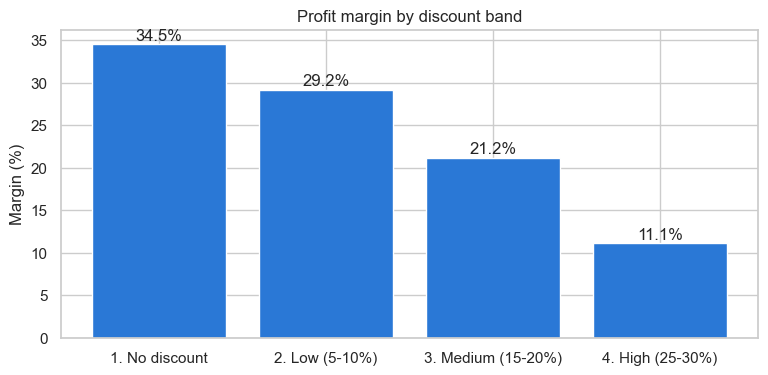

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(result["discount_band"], result["margin_pct"], color=MAIN_COLOR)
ax.set_title("Profit margin by discount band")
ax.set_ylabel("Margin (%)")
for i, v in enumerate(result["margin_pct"]):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
plt.show()

**Answer:** The margin drops from 34.5% with no discount to 11.1% with high discounts, but the average units per line stays at ~1.75 in every band.
**Discounts are not making customers buy more**, they only reduce profit.

### Q8. Which products are being sold at a loss, and how much do we lose?

*SQL used:* Simple `WHERE` filter before the `GROUP BY`.

In [11]:
query = """
SELECT
    p.product_name,
    oi.discount,
    COUNT(*)                 AS lines_at_loss,
    ROUND(SUM(oi.sales), 0)  AS revenue,
    ROUND(SUM(oi.profit), 0) AS total_loss
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
WHERE oi.profit < 0
GROUP BY p.product_name, oi.discount
ORDER BY total_loss;
"""

result = run_query(query)
result

,product_name,discount,lines_at_loss,revenue,total_loss
0,MacBook Air M3,0.3,56,86384.0,-3867.0
1,Dell XPS 15,0.3,54,76376.0,-2794.0
2,HP Spectre x360,0.3,53,65391.0,-2610.0
3,Samsung Galaxy S24,0.3,46,48659.0,-1801.0
4,iPhone 15,0.3,43,40905.0,-1346.0
5,Google Pixel 8,0.3,53,47951.0,-69.0


**Answer:** Only phones and laptops with a **30% discount** are sold at a loss (305 lines, ~12.5K USD lost). The loss is small in money, but it shows that the
discount policy has no limit based on the product cost - all phones and laptops have a margin below 30%, so a 30% discount on them will always lose money.

## C. Customers

### Q9. Who are the 10 best customers?

*SQL used:* `JOIN` of 3 tables (customers -> orders -> order_items) and `LIMIT`.

In [12]:
query = """
SELECT
    c.customer_id,
    c.customer_name,
    c.segment,
    c.state,
    COUNT(DISTINCT o.order_id) AS orders,
    ROUND(SUM(oi.sales), 0)    AS revenue,
    ROUND(SUM(oi.profit), 0)   AS profit
FROM customers c
JOIN orders o       ON c.customer_id = o.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
GROUP BY c.customer_id, c.customer_name, c.segment, c.state
ORDER BY revenue DESC
LIMIT 10;
"""

result = run_query(query)
result

,customer_id,customer_name,segment,state,orders,revenue,profit
0,CUST-06526,Crystal Pierce,Consumer,Oregon,17,30081.0,7894.0
1,CUST-00631,Rhonda Chavez,Corporate,Wisconsin,23,29774.0,7510.0
2,CUST-07834,Heather Williams,Consumer,Washington,19,28516.0,7857.0
3,CUST-07328,Austin Perez,Consumer,California,24,27671.0,7336.0
4,CUST-02151,Walter Hansen,Home Office,Florida,10,26246.0,6826.0
5,CUST-07890,Greg Dyer,Home Office,Florida,20,24238.0,5874.0
6,CUST-06002,Miranda Beck,Consumer,Connecticut,12,23549.0,6600.0
7,CUST-04278,Jennifer Lopez,Corporate,Florida,19,23542.0,6474.0
8,CUST-04326,Glenn Chen,Corporate,Colorado,21,23198.0,6605.0
9,CUST-02302,Jennifer Baker,Home Office,Illinois,21,23173.0,5263.0


**Answer:** The best customers spend between 23K and 30K USD in 2 years. They come from all 3 segments and from different states,
so there is no single "type" of top customer - what they have in common is buying expensive tech products.

### Q10. How are customers split by how often they buy, and how much is each group worth?

*SQL used:* A CTE with one row per customer, then `CASE WHEN` to create groups and subqueries to calculate the percentages.

In [13]:
query = """
WITH customer_orders AS (
    SELECT
        o.customer_id,
        COUNT(DISTINCT o.order_id) AS n_orders,
        SUM(oi.sales)              AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY o.customer_id
)
SELECT
    CASE
        WHEN n_orders = 1   THEN '1. One-time (1 order)'
        WHEN n_orders <= 5  THEN '2. Occasional (2-5 orders)'
        WHEN n_orders <= 10 THEN '3. Regular (6-10 orders)'
        ELSE                     '4. Loyal (11+ orders)'
    END                                                                  AS customer_group,
    COUNT(*)                                                             AS customers,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM customer_orders), 1)  AS pct_customers,
    ROUND(SUM(revenue) * 100.0 / (SELECT SUM(revenue) FROM customer_orders), 1) AS pct_revenue,
    ROUND(AVG(revenue), 0)                                               AS avg_revenue_per_customer
FROM customer_orders
GROUP BY customer_group
ORDER BY customer_group;
"""

result = run_query(query)
result

,customer_group,customers,pct_customers,pct_revenue,avg_revenue_per_customer
0,1. One-time (1 order),174,2.2,0.3,554.0
1,2. Occasional (2-5 orders),3254,40.9,20.3,2227.0
2,3. Regular (6-10 orders),2724,34.2,33.9,4444.0
3,4. Loyal (11+ orders),1810,22.7,45.6,8997.0


**Answer:** Only 2.2% of the customers bought once. The **"Loyal" group (11+ orders) is 22.7% of the customers but 45.6% of the revenue**,
and each of these customers is worth on average ~9K USD - about 4 times more than an occasional customer.

### Q11. How many new customers do we get each month?

*SQL used:* `MIN()` to find the first order of each customer - the month of that order is when the customer was acquired.

In [14]:
query = """
WITH first_order AS (
    SELECT
        customer_id,
        MIN(order_date) AS first_order_date
    FROM orders
    GROUP BY customer_id
)
SELECT
    strftime('%Y-%m', first_order_date) AS month,
    COUNT(*)                            AS new_customers
FROM first_order
GROUP BY month
ORDER BY month;
"""

result = run_query(query)
result

,month,new_customers
0,2023-01,1392
1,2023-02,1000
2,2023-03,1183
3,2023-04,908
4,2023-05,687
5,2023-06,531
6,2023-07,463
7,2023-08,328
8,2023-09,260
9,2023-10,221


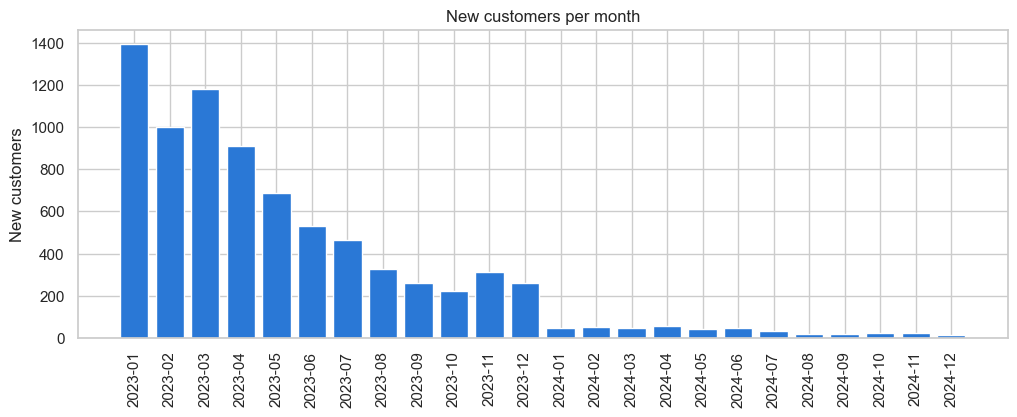

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(result["month"], result["new_customers"], color=MAIN_COLOR)
ax.set_title("New customers per month")
ax.set_ylabel("New customers")
ax.tick_params(axis="x", rotation=90)
plt.savefig("../images/new_customers.png", dpi=120, bbox_inches="tight")
plt.show()

**Answer:** This is the most worrying result of the analysis. Almost all customers were acquired in **2023** (more than 1,000 per month at the start),
and in **2024 the company got only a few dozen new customers per month**. The revenue is being kept only by the existing customers buying again.
This explains why the business is not growing: **there is practically no new customer acquisition.**

*(Careful when reading the 2023 numbers: the data starts in January 2023, so customers who already bought before that date also appear as "new" in the
first months. That's why 2023 starts so high. But even taking this into account, the 2024 numbers are very low.)*

*(Note: since the data is fictional, this may come from the way it was generated - a fixed list of customers. In a real company this would be the first thing to investigate.)*

### Q12. How does each region contribute to revenue and profit?

*SQL used:* Window function over an aggregate: `SUM(SUM(sales)) OVER ()` gives the grand total in every row, to calculate the % of the total.

In [16]:
query = """
SELECT
    c.region,
    COUNT(DISTINCT c.customer_id)                                   AS customers,
    ROUND(SUM(oi.sales), 0)                                         AS revenue,
    ROUND(SUM(oi.sales) * 100.0 / SUM(SUM(oi.sales)) OVER (), 1)    AS pct_of_revenue,
    ROUND(SUM(oi.profit) * 100.0 / SUM(oi.sales), 1)                AS margin_pct,
    ROUND(SUM(oi.sales) / COUNT(DISTINCT c.customer_id), 0)         AS revenue_per_customer
FROM order_items oi
JOIN orders o    ON oi.order_id = o.order_id
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.region
ORDER BY revenue DESC;
"""

result = run_query(query)
result

,region,customers,revenue,pct_of_revenue,margin_pct,revenue_per_customer
0,South,2605,11702874.0,32.8,28.8,4492.0
1,West,2071,9369338.0,26.2,28.7,4524.0
2,Northeast,1805,8024912.0,22.5,28.8,4446.0
3,Midwest,1481,6636340.0,18.6,28.7,4481.0


**Answer:** The South has the biggest share (32.8%) because it has the most customers. The margin (~28.8%) and the revenue per customer (~4.5K USD)
are practically the same in every region, so there is no "better" or "worse" region - only bigger and smaller markets.

## D. Operations

### Q13. How long does each shipping mode take, and is "Same Day" really same day?

*SQL used:* Date difference with `julianday()` (SQLite has no `DATEDIFF`) and counting with `SUM(CASE WHEN ...)`.

In [17]:
query = """
SELECT
    ship_mode,
    COUNT(*)                                                     AS orders,
    ROUND(AVG(julianday(ship_date) - julianday(order_date)), 2)  AS avg_days_to_ship,
    ROUND(AVG(julianday(deliver_date) - julianday(order_date)), 2) AS avg_days_to_deliver,
    SUM(CASE WHEN ship_date = order_date THEN 1 ELSE 0 END)      AS shipped_on_order_day
FROM orders
GROUP BY ship_mode
ORDER BY avg_days_to_deliver;
"""

result = run_query(query)
result

,ship_mode,orders,avg_days_to_ship,avg_days_to_deliver,shipped_on_order_day
0,Same Day,2987,1.49,2.49,0
1,First Class,9103,1.50,3.50,0
2,Second Class,12160,1.50,5.01,0
3,Standard Class,35750,1.50,7.49,0


**Answer:** The delivery times are consistent with the shipping mode (2.5 days for Same Day up to 7.5 days for Standard Class).
But **not a single "Same Day" order (0 out of 2,987) was shipped on the day it was ordered.** If customers pay extra for this option, this is a service problem.

### Q14. What is the return rate by category, and how much revenue is returned?

*SQL used:* `AVG()` of a 0/1 column gives a rate directly, plus conditional aggregation for the returned revenue.

In [18]:
query = """
SELECT
    p.category,
    COUNT(*)                                                          AS lines,
    SUM(oi.is_returned)                                               AS returned_lines,
    ROUND(AVG(oi.is_returned) * 100, 1)                               AS return_rate_pct,
    ROUND(SUM(CASE WHEN oi.is_returned = 1 THEN oi.sales ELSE 0 END), 0) AS returned_revenue
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
GROUP BY p.category
ORDER BY return_rate_pct DESC;
"""

result = run_query(query)
result

,category,lines,returned_lines,return_rate_pct,returned_revenue
0,Office Supplies,40314,3242,8.0,68799.0
1,Technology,24395,1409,5.8,1660539.0
2,Furniture,16206,826,5.1,368414.0


**Answer:** Office Supplies have the highest return rate (8.0%), but they represent only ~69K USD of returned revenue.
**Technology has a lower rate (5.8%) but 1.66M USD returned** - almost 80% of all returned revenue. To reduce the money lost with returns,
the focus should be on laptops and phones.

In [19]:
conn.close()

## Summary

The SQL analysis confirms the results of the EDA and adds new information:

| Topic | Main finding |
|---|---|
| Growth | Revenue flat between 2023 and 2024 (~17.9M USD per year) |
| New customers | Almost no new customers in 2024 - the main reason for the lack of growth |
| Seasonality | ~33% of the revenue in Nov-Dec, equal in all categories |
| Margin | Laptops and Phones are the only sub-categories below the company margin |
| Discounts | Don't increase units sold; 30% off on tech = sale at a loss |
| Customers | Loyal customers (11+ orders) = 23% of customers, 46% of revenue |
| Shipping | "Same Day" never ships on the same day |
| Returns | 80% of the returned revenue is Technology |

See the full list of conclusions and recommendations in the [README](../README.md).